# Importacion de Librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga y Exploracion de Datos

In [2]:
variables_macro = pd.read_excel('Macro Variables_Prueba_CD.xlsx')
volumen = pd.read_excel('Volume Data_prueba_CD.xlsx', sheet_name='Marca')

print(f'''Dataframe volumen:
El dataframe tiene {volumen.shape[0]} filas y {volumen.shape[1]} columnas.
''')
display(volumen.head(5))
print(f'''Dataframe variables_macro:
El dataframe tiene {variables_macro.shape[0]} filas y {variables_macro.shape[1]} columnas.
''')
display(variables_macro.head(5))

Dataframe volumen:
El dataframe tiene 324 filas y 6 columnas.



,Año,Mes,Marca,Volume,NR,DN
0,2023,1,Marca 1,5405.309564,4.450753e+05,2670
1,2023,1,Marca 2,76184.199271,8.086892e+06,5443
2,2023,1,Marca 3,9005.347750,1.085043e+06,4120
3,2023,1,Marca 4,34901.062904,4.025846e+06,4817
4,2023,1,Marca 5,4080.766579,6.585441e+05,3481


Dataframe variables_macro:
El dataframe tiene 87 filas y 5 columnas.



,date,concept,scale,frequency,value
0,2023-01-01,Broad Money,billions,annual,37.948650
1,2023-01-01,Broad Money,billions,quarterly,45.918736
2,2023-01-01,CPI,unit,annual,100.055148
3,2023-01-01,CPI,unit,quarterly,99.037360
4,2023-01-01,CPI,unit,monthly,98.744918


In [3]:
# Revision del tipo de datos y faltantes para el DataFrame de volumen
volumen.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 324 entries, 0 to 323
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Año     324 non-null    int64  
 1   Mes     324 non-null    int64  
 2   Marca   324 non-null    object 
 3   Volume  324 non-null    float64
 4   NR      324 non-null    float64
 5   DN      324 non-null    int64  
dtypes: float64(2), int64(3), object(1)
memory usage: 15.3+ KB


In [4]:
#  Revision del tipo de datos y faltantes para el DataFrame de variables macroeconomicas
variables_macro.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       87 non-null     datetime64[ns]
 1   concept    87 non-null     object        
 2   scale      87 non-null     object        
 3   frequency  87 non-null     object        
 4   value      87 non-null     float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 3.5+ KB


In [5]:
# Revision de cuantos años y meses tenemos disponibles con informacion del volumen
volumen.groupby(['Año','Mes']).agg({'Volume':'sum'}).reset_index()

,Año,Mes,Volume
0,2023,1,139796.051369
1,2023,2,158549.471359
2,2023,3,221631.443417
3,2023,4,187586.451825
4,2023,5,198868.406978
5,2023,6,194688.737361
6,2023,7,163291.793902
7,2023,8,164963.546272
8,2023,9,184913.442942
9,2023,10,174705.506005


*Tenemos información de volumen mensual para 3 años (2023-2025)*

In [6]:
# Creacion de Columnas Año y Mes en el DataFrame de variables macroeconomicas
variables_macro = variables_macro.assign(
    Año = pd.to_datetime(variables_macro['date']).dt.year,
    Mes = pd.to_datetime(variables_macro['date']).dt.month
)

# Revision de cuantos años y meses tenemos disponibles con informacion de variables macroeconomicas
display(variables_macro.groupby(['Año','Mes'])['concept'].unique().reset_index())

,Año,Mes,concept
0,2023,1,"[Broad Money, CPI, GDP, Savings, Unemployment ..."
1,2023,2,[CPI]
2,2023,3,[CPI]
3,2023,4,"[Broad Money, CPI, GDP]"
4,2023,5,[CPI]
5,2023,6,[CPI]
6,2023,7,"[Broad Money, CPI, GDP]"
7,2023,8,[CPI]
8,2023,9,[CPI]
9,2023,10,"[Broad Money, CPI, GDP]"


*Tenemos información de variables macroeconómicas para 3 años (2023-2025)*

In [7]:
# Revision de la temporalidad de las variables macroeconomicas

for variable in variables_macro['concept'].unique():
    data = variables_macro[variables_macro['concept'] == variable]
    print(f'Variable: {variable}')
    display(data.groupby(['Año','Mes'])['frequency'].unique().reset_index())

Variable: Broad Money


,Año,Mes,frequency
0,2023,1,"[annual, quarterly]"
1,2023,4,[quarterly]
2,2023,7,[quarterly]
3,2023,10,[quarterly]
4,2024,1,"[annual, quarterly]"
5,2024,4,[quarterly]
6,2024,7,[quarterly]
7,2024,10,[quarterly]
8,2025,1,"[quarterly, annual]"
9,2025,4,[quarterly]


Variable: CPI


,Año,Mes,frequency
0,2023,1,"[annual, quarterly, monthly]"
1,2023,2,[monthly]
2,2023,3,[monthly]
3,2023,4,"[quarterly, monthly]"
4,2023,5,[monthly]
5,2023,6,[monthly]
6,2023,7,"[monthly, quarterly]"
7,2023,8,[monthly]
8,2023,9,[monthly]
9,2023,10,"[monthly, quarterly]"


Variable: GDP


,Año,Mes,frequency
0,2023,1,"[annual, quarterly]"
1,2023,4,[quarterly]
2,2023,7,[quarterly]
3,2023,10,[quarterly]
4,2024,1,"[annual, quarterly]"
5,2024,4,[quarterly]
6,2024,7,[quarterly]
7,2024,10,[quarterly]
8,2025,1,"[annual, quarterly]"
9,2025,4,[quarterly]


Variable: Savings


,Año,Mes,frequency
0,2023,1,[annual]
1,2024,1,[annual]
2,2025,1,[annual]


Variable: Unemployment Rate


,Año,Mes,frequency
0,2023,1,[annual]
1,2024,1,[annual]
2,2025,1,[annual]


- *Las variables `Savings` y `Unemployment Rate` estan solo en temporalidad anual*
- *Las variables `Broad Money` y `GDP` esta en temportaliad trimestral y anual
- *La variable `CPI` esta en temporalidad mensual, trimestral y anual


In [8]:
# Revision variables trimestrales

for variable in ['GDP','Broad Money']:
    print(f'Variable: {variable}')
    display(variables_macro[variables_macro['concept'] == variable].groupby(['Año','Mes','frequency','scale'])['value'].sum().reset_index())

Variable: GDP


,Año,Mes,frequency,scale,value
0,2023,1,annual,billions,40.736359
1,2023,1,quarterly,billions,38.207765
2,2023,4,quarterly,billions,39.801554
3,2023,7,quarterly,billions,42.115131
4,2023,10,quarterly,billions,42.820987
5,2024,1,annual,billions,45.124823
6,2024,1,quarterly,billions,43.101433
7,2024,4,quarterly,billions,44.001074
8,2024,7,quarterly,billions,45.971930
9,2024,10,quarterly,billions,47.185175


Variable: Broad Money


,Año,Mes,frequency,scale,value
0,2023,1,annual,billions,37.948650
1,2023,1,quarterly,billions,45.918736
2,2023,4,quarterly,billions,36.831127
3,2023,7,quarterly,billions,37.959337
4,2023,10,quarterly,billions,37.445311
5,2024,1,annual,billions,38.027920
6,2024,1,quarterly,billions,37.604812
7,2024,4,quarterly,billions,38.775352
8,2024,7,quarterly,billions,38.269580
9,2024,10,quarterly,billions,37.554046


In [9]:
# Revision de la variable mensual,trimestra, anual

variables_macro[variables_macro['concept'] == 'CPI'].groupby(['Año','Mes','frequency','scale'])['value'].sum().reset_index()

,Año,Mes,frequency,scale,value
0,2023,1,annual,unit,100.055148
1,2023,1,monthly,unit,98.744918
2,2023,1,quarterly,unit,99.037360
3,2023,2,monthly,unit,99.075215
4,2023,3,monthly,unit,99.291946
5,2023,4,monthly,unit,99.367999
6,2023,4,quarterly,unit,99.501702
7,2023,5,monthly,unit,99.482510
8,2023,6,monthly,unit,99.654597
9,2023,7,monthly,unit,100.109923


- *Las variables trimestrales tienen la particularidad que tambien agregan la variable anualizada*
- *La variable `CPI` tiene la misma particualridad de las variables trimestrales, agrega una variable anualizada pero también una variable trimestral*

# Definicion de la marca principal

In [ ]:
volumen.Marca.value_counts()

Marca
Marca 1     36
Marca 2     36
Marca 3     36
Marca 4     36
Marca 5     36
Marca 6     36
Marca 7     36
Marca 8     36
Marca 9     13
Marca 10    12
Marca 11    11
Name: count, dtype: int64

*No todas las 11 marcas estan para todos los meses/años*

In [50]:
brands_general = volumen.groupby('Marca').agg({
    'Volume': 'sum',
    'NR': 'sum',
    'DN': 'mean'
})

brands_general['volume_share'] = (
    brands_general['Volume'] / brands_general['Volume'].sum()
)

brands_general['NR_share'] = (
    brands_general['NR'] / brands_general['NR'].sum()
)

brands_general = brands_general.sort_values(
    by='Volume', ascending=False
)

brands_general

,Volume,NR,DN,volume_share,NR_share
Marca,,,,,
Marca 2,2.274453e+06,2.525365e+08,5883.833333,0.398091,0.365739
Marca 4,1.487513e+06,1.691315e+08,4454.138889,0.260355,0.244947
Marca 3,7.454314e+05,9.558270e+07,4525.000000,0.130471,0.138429
Marca 1,3.920894e+05,3.756712e+07,2332.666667,0.068626,0.054407
Marca 5,2.448899e+05,3.705118e+07,3017.444444,0.042862,0.053660
Marca 6,2.386993e+05,4.840611e+07,3256.416667,0.041779,0.070105
Marca 7,2.184515e+05,3.246595e+07,2494.194444,0.038235,0.047019
Marca 8,1.115420e+05,1.778141e+07,2389.305556,0.019523,0.025752
Marca 11,3.134249e+02,4.177467e+04,55.181818,0.000055,0.000061


In [ ]:
brands = volumen.groupby(['Año', 'Marca']).agg({'Volume': 'sum', 'NR': 'sum', 'DN':'mean'})

brands['volume_share'] = brands['Volume'] / brands.groupby('Año')['Volume'].transform('sum')
brands['NR_share'] = brands['NR'] / brands.groupby('Año')['NR'].transform('sum')
brands = brands.sort_values(
    by=['Año', 'Volume'],
    ascending=[True, False]
)

brands

Volume            NR           DN  volume_share  NR_share
Año  Marca                                                                    
2023 Marca 2   1.099030e+06  1.198171e+08  6065.333333      0.494933  0.454503
     Marca 4   4.954355e+05  5.593951e+07  4735.250000      0.223112  0.212196
     Marca 3   2.151771e+05  2.592153e+07  4734.750000      0.096902  0.098328
     Marca 5   1.120009e+05  1.676385e+07  3783.833333      0.050438  0.063590
     Marca 1   9.322453e+04  8.194043e+06  2164.666667      0.041982  0.031083
     Marca 6   9.248513e+04  1.889652e+07  3971.500000      0.041649  0.071680
     Marca 8   5.735519e+04  9.127355e+06  3591.250000      0.025829  0.034623
     Marca 7   5.580546e+04  8.956060e+06  2584.750000      0.025131  0.033973
     Marca 9   5.133967e+01  6.429552e+03     2.166667      0.000023  0.000024
2024 Marca 2   7.266636e+05  7.772386e+07  6340.916667      0.385299  0.354557
     Marca 4   4.498422e+05  4.826132e+07  3801.333333      0.238520  0.220156
     Marca 3   2.429088e+05  3.072109e+07  4252.333333      0.128798  0.140142
     Marca 1   1.465627e+05  1.397321e+07  2157.833333      0.077712  0.063742
     Marca 7   1.110371e+05  1.542913e+07  2583.333333      0.058875  0.070384
     Marca 6   9.397125e+04  1.716362e+07  3099.750000      0.049826  0.078296
     Marca 5   7.294877e+04  1.021416e+07  2797.750000      0.038680  0.046595
     Marca 8   4.207582e+04  5.815958e+06  2273.416667      0.022310  0.026531
     Marca 9   0.000000e+00  0.000000e+00     0.000000      0.000000  0.000000
     Marca 10 -3.659793e+01 -8.852329e+04    45.454545     -0.000019 -0.000404
2025 Marca 4   5.422354e+05  6.493067e+07  4825.833333      0.337451  0.312699
     Marca 2   4.487594e+05  5.499554e+07  5245.250000      0.279277  0.264852
     Marca 3   2.873455e+05  3.894008e+07  4587.916667      0.178824  0.187531
     Marca 1   1.523022e+05  1.539987e+07  2675.500000      0.094783  0.074164
     Marca 5   5.994030e+04  1.007317e+07  2470.750000      0.037303  0.048511
     Marca 6   5.224294e+04  1.234597e+07  2698.000000      0.032512  0.059457
     Marca 7   5.160891e+04  8.080768e+06  2314.500000      0.032118  0.038916
     Marca 8   1.211094e+04  2.838101e+06  1303.250000      0.007537  0.013668
     Marca 11  3.134249e+02  4.177467e+04    55.181818      0.000195  0.000201
     Marca 10  0.000000e+00  0.000000e+00     0.000000      0.000000  0.000000

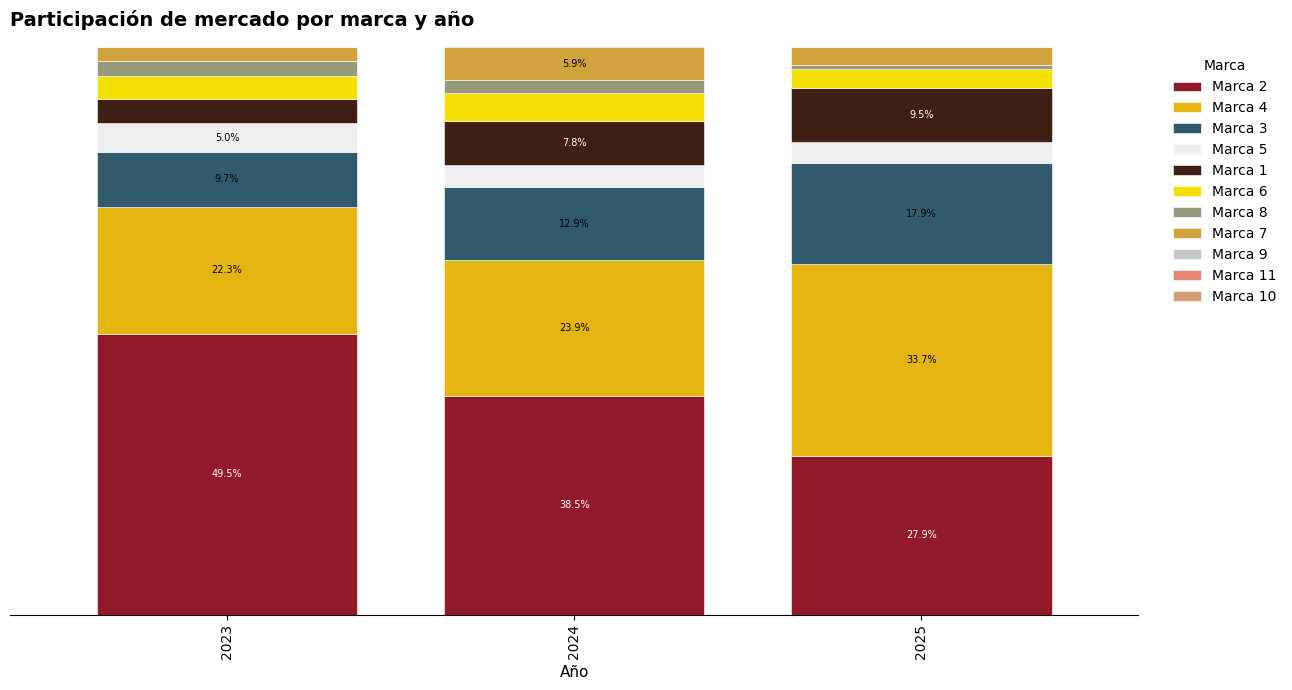

In [34]:
from matplotlib.ticker import PercentFormatter

# Paleta oficial AB InBev
colores_abi = [
    '#921A28',  # 1. Rojo
    '#E5B611',  # 2. Dorado
    '#325A6D',  # 3. Azul
    '#EFEFEF',  # 4. Gris claro
    '#3F1F14',  # 5. Marrón
    '#F5E003',  # 6. Amarillo
    '#959B7B',  # 7. Verde
    '#D1A33C',  # 8. Dorado oscuro
    '#C7C7C7',  # 9. Gris oscuro
    '#E88475',  # 10. Rojo claro
    '#D69E77'   # 11. Beige
]

# Participación de mercado por marca
df_plot = brands['volume_share'].unstack('Marca').fillna(0)

# Ordenar las marcas por participación en 2023
orden = df_plot.loc[2023].sort_values(
    ascending=False
).index

df_plot = df_plot[orden]

# Asociar un color fijo a cada marca
colores_por_marca = dict(zip(orden, colores_abi))

ax = df_plot.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 7),
    color=[colores_por_marca[m] for m in df_plot.columns],
    edgecolor='white',
    linewidth=0.4,
    width=0.75
)

# Etiquetas de participación
for i, container in enumerate(ax.containers):
    marca = df_plot.columns[i]
    color_fondo = colores_por_marca[marca]

    # Letra blanca para rojo y marrón; negra para el resto
    color_texto = (
        'white'
        if color_fondo in ['#921A28', '#3F1F14']
        else 'black'
    )

    labels = [
            f'{v:.1%}' if v >= 0.05 else ''
            for v in container.datavalues
        ]

    ax.bar_label(
        container,
        labels=labels,
        label_type='center',
        fontsize=7,
        color=color_texto,
        padding=0
    )

# Formato del gráfico
ax.set_xlabel('Año', fontsize=11)
ax.set_ylabel('Participación de mercado', fontsize=11)
ax.set_title(
    'Participación de mercado por marca y año',
    fontsize=14,
    fontweight='bold',
    loc='left',
    pad=15
)

ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.legend(
    title='Marca',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=False
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)
ax.get_yaxis().set_visible(False)
plt.tight_layout()
plt.show()

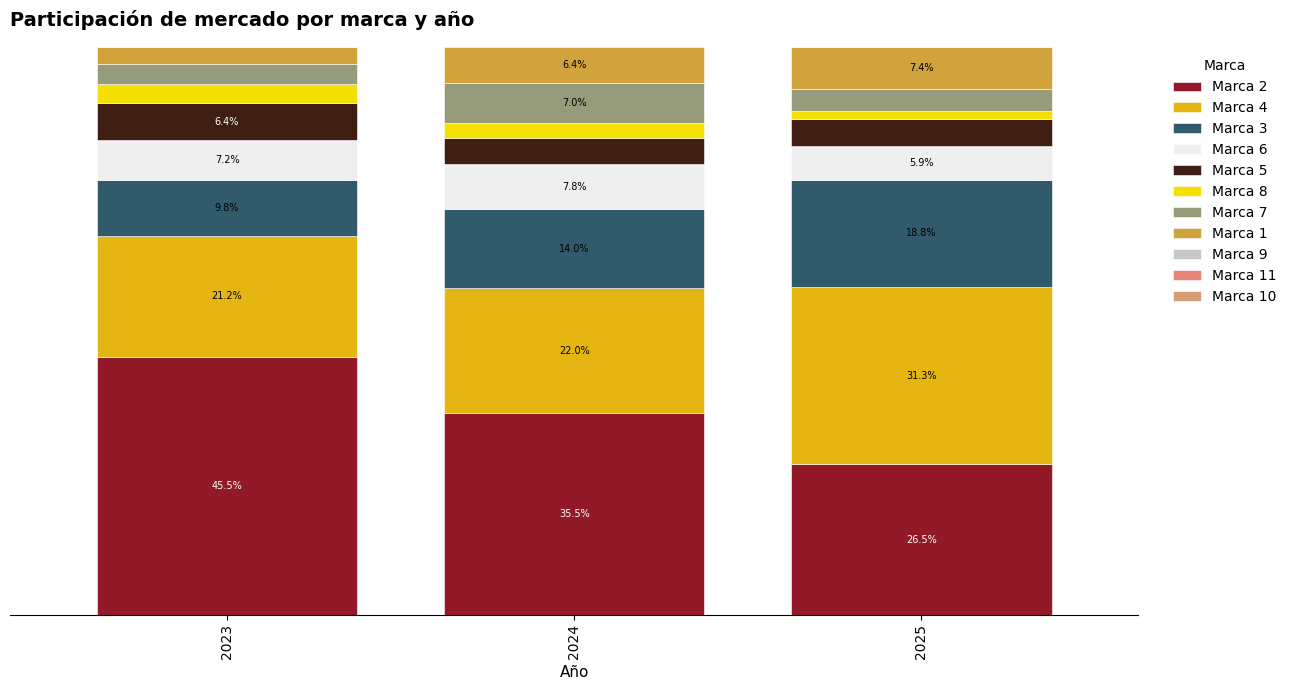

In [35]:
# Paleta oficial AB InBev
colores_abi = [
    '#921A28',  # 1. Rojo
    '#E5B611',  # 2. Dorado
    '#325A6D',  # 3. Azul
    '#EFEFEF',  # 4. Gris claro
    '#3F1F14',  # 5. Marrón
    '#F5E003',  # 6. Amarillo
    '#959B7B',  # 7. Verde
    '#D1A33C',  # 8. Dorado oscuro
    '#C7C7C7',  # 9. Gris oscuro
    '#E88475',  # 10. Rojo claro
    '#D69E77'   # 11. Beige
]

# Participación de mercado por marca
df_plot = brands['NR_share'].unstack('Marca').fillna(0)

# Ordenar las marcas por participación en 2023
orden = df_plot.loc[2023].sort_values(
    ascending=False
).index

df_plot = df_plot[orden]

# Asociar un color fijo a cada marca
colores_por_marca = dict(zip(orden, colores_abi))

ax = df_plot.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 7),
    color=[colores_por_marca[m] for m in df_plot.columns],
    edgecolor='white',
    linewidth=0.4,
    width=0.75
)

# Etiquetas de participación
for i, container in enumerate(ax.containers):
    marca = df_plot.columns[i]
    color_fondo = colores_por_marca[marca]

    # Letra blanca para rojo y marrón; negra para el resto
    color_texto = (
        'white'
        if color_fondo in ['#921A28', '#3F1F14']
        else 'black'
    )

    labels = [
            f'{v:.1%}' if v >= 0.05 else ''
            for v in container.datavalues
        ]

    ax.bar_label(
        container,
        labels=labels,
        label_type='center',
        fontsize=7,
        color=color_texto,
        padding=0
    )

# Formato del gráfico
ax.set_xlabel('Año', fontsize=11)
ax.set_ylabel('Participación de mercado', fontsize=11)
ax.set_title(
    'Participación de mercado por marca y año',
    fontsize=14,
    fontweight='bold',
    loc='left',
    pad=15
)

ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.legend(
    title='Marca',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=False
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)
ax.get_yaxis().set_visible(False)
plt.tight_layout()
plt.show()

# Validacion de Estacionalidad del Volumen

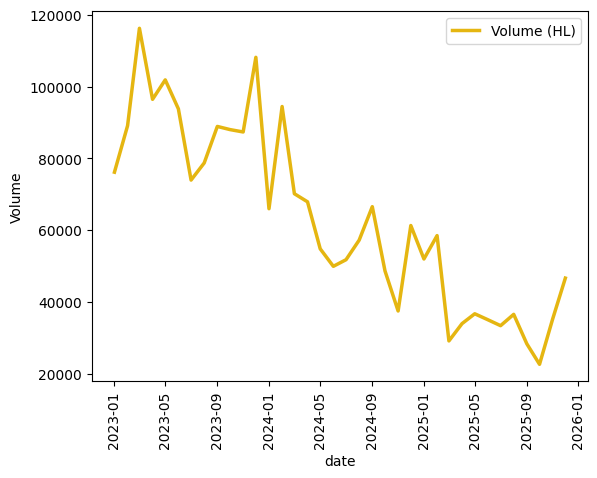

In [41]:
volumen['date'] = pd.to_datetime(
    dict(
        year=volumen["Año"],
        month=volumen["Mes"],
        day=1
    )
)

main_brand = volumen[volumen.Marca == 'Marca 2']

sns.lineplot(data=main_brand, x="date", y="Volume", 
             color='#e5b611', linewidth=2.5, label='Volume (HL)')
plt.xticks(rotation=90)
plt.show()

C:\Users\CO588951\AppData\Local\Temp\ipykernel_16348\731081509.py:18: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  resultado = seasonal_decompose(


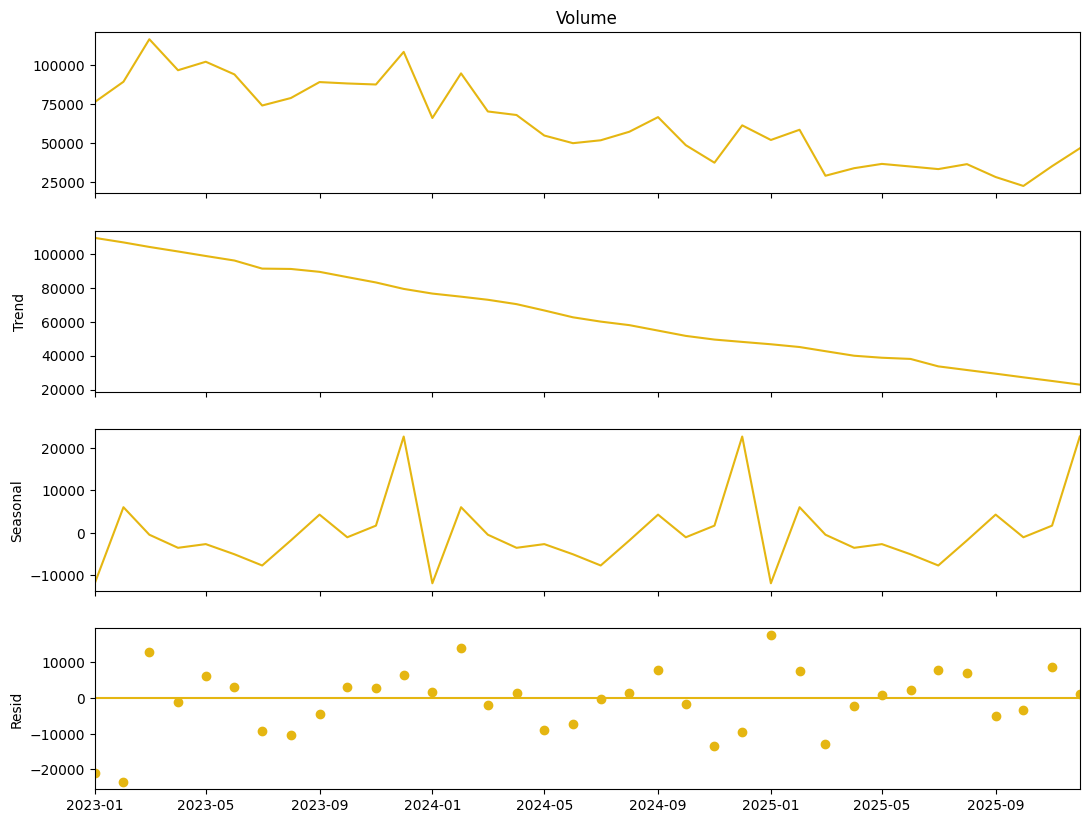

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

volume_seasonal = main_brand.copy()

volume_seasonal["date"] = pd.to_datetime(
    volume_seasonal["date"]
)

volume_seasonal = (
    volume_seasonal
    .sort_values("date")
    .set_index("date")
    .asfreq("MS")
)

resultado = seasonal_decompose(
    volume_seasonal["Volume"],
    model="additive",
    period=12,
    extrapolate_trend="freq"
)

fig = resultado.plot()
fig.set_size_inches(12, 9)
for ax in fig.axes:
    for line in ax.lines:
        line.set_color("#e5b611")

plt.show()

In [43]:
import numpy as np

seasonal = resultado.seasonal.dropna()
residual = resultado.resid.dropna()

common_index = seasonal.index.intersection(
    residual.index
)

seasonal = seasonal.loc[common_index]
residual = residual.loc[common_index]

seasonal_strength = max(
    0,
    1 - (
        np.var(residual, ddof=1)
        / np.var(
            seasonal + residual,
            ddof=1
        )
    )
)

print(
    f"Fuerza estacional: {seasonal_strength:.3f}"
)

Fuerza estacional: 0.464


    MONTH_NAME  SEASONAL_EFFECT
11   Diciembre     22743.562327
1      Febrero      6014.314855
8   Septiembre      4260.867667
10   Noviembre      1649.579570
2        Marzo      -497.251376
9      Octubre     -1102.113367
7       Agosto     -1848.223299
4         Mayo     -2721.730640
3        Abril     -3597.008515
5        Junio     -5127.728842
6        Julio     -7780.138278
0        Enero    -11994.130102


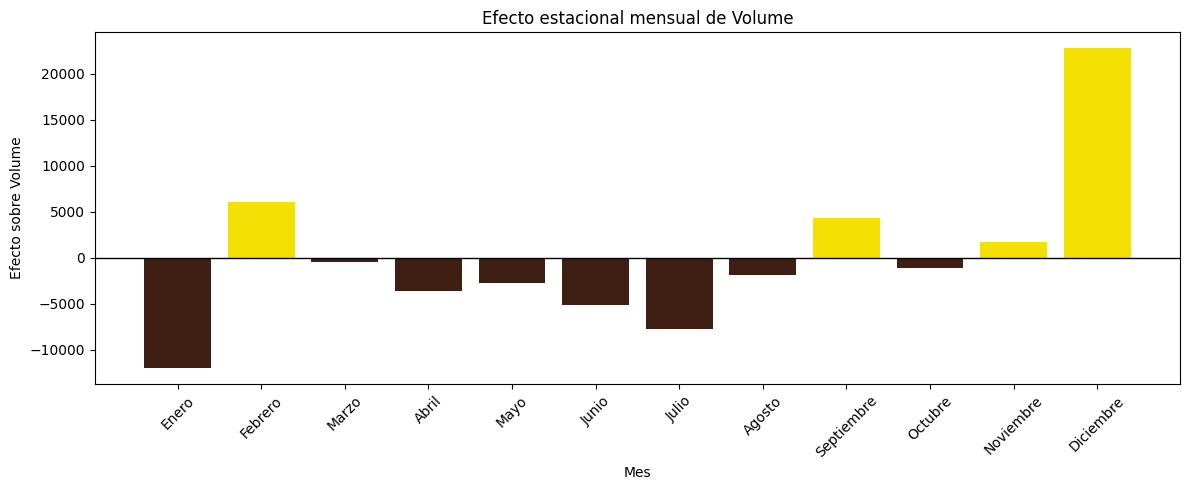

In [44]:
seasonal_monthly = (
    resultado.seasonal
    .groupby(resultado.seasonal.index.month)
    .mean()
    .rename("SEASONAL_EFFECT")
    .reset_index()
    .rename(columns={"date": "MONTH"})
)

seasonal_monthly["MONTH_NAME"] = [
    "Enero",
    "Febrero",
    "Marzo",
    "Abril",
    "Mayo",
    "Junio",
    "Julio",
    "Agosto",
    "Septiembre",
    "Octubre",
    "Noviembre",
    "Diciembre"
]

seasonal_monthly = seasonal_monthly[
    [
        "MONTH_NAME",
        "SEASONAL_EFFECT"
    ]
]

print(
    seasonal_monthly
    .sort_values(
        "SEASONAL_EFFECT",
        ascending=False
    )
)

seasonal_plot = seasonal_monthly.copy()

fig, ax = plt.subplots(figsize=(12, 5))

colors = np.where(
    seasonal_plot["SEASONAL_EFFECT"] >= 0,
    "#f5e003",
    "#3f1f14"
)

ax.bar(
    seasonal_plot["MONTH_NAME"],
    seasonal_plot["SEASONAL_EFFECT"],
    color=colors
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Efecto estacional mensual de Volume"
)

ax.set_xlabel("Mes")
ax.set_ylabel("Efecto sobre Volume")
ax.tick_params(
    axis="x",
    rotation=45
)

plt.tight_layout()
plt.show()

YEAR    2023   2024   2025
MONTH                     
1      0.832  1.090  1.391
2      0.973  1.560  1.565
3      1.269  1.159  0.781
4      1.053  1.122  0.910
5      1.113  0.906  0.983
6      1.024  0.825  0.938
7      0.808  0.856  0.894
8      0.860  0.946  0.979
9      0.971  1.100  0.759
10     0.961  0.804  0.607
11     0.954  0.620  0.944
12     1.181  1.013  1.249


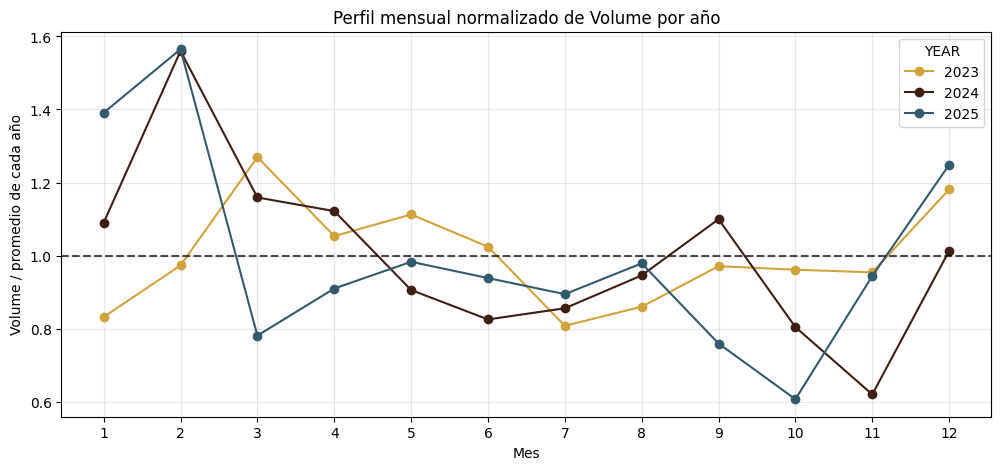

In [45]:
comparison = main_brand.copy()

comparison["date"] = pd.to_datetime(
    comparison["date"]
)

comparison["YEAR"] = comparison["date"].dt.year
comparison["MONTH"] = comparison["date"].dt.month

comparison["YEAR_MEAN"] = (
    comparison
    .groupby("YEAR")["Volume"]
    .transform("mean")
)

comparison["VOLUME_INDEX"] = (
    comparison["Volume"]
    / comparison["YEAR_MEAN"]
)

profile = comparison.pivot(
    index="MONTH",
    columns="YEAR",
    values="VOLUME_INDEX"
)

print(profile.round(3))

fig, ax = plt.subplots(figsize=(12, 5))

profile.plot(
    ax=ax,
    marker="o",
    color=["#d1a33c", "#3f1f14", "#325a6d"]
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    alpha=0.7
)

ax.set_title(
    "Perfil mensual normalizado de Volume por año"
)

ax.set_xlabel("Mes")
ax.set_ylabel(
    "Volume / promedio de cada año"
)

ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)

plt.show()